# CALCE CX2 — Cross-cell Latent-State Forecasting Study

**Next-cycle SOH forecasting · 5 selected charging features · battery-disjoint outer evaluation**

This notebook extends the earlier LatentTSF-inspired experiment. It answers whether latent-state forecasting consistently beats a direct Transformer **across different held-out batteries**, and whether latent dimension or end-to-end encoder fine-tuning changes the result.

### Four model families
1. **Direct Transformer**: no autoencoder, historical five features → next-cycle SOH.
2. **Frozen latent-only**: train-only observation autoencoder, frozen encoder → Transformer → SOH.
3. **Fine-tuned latent-only**: initialize from the pretrained encoder; fine-tune encoder along with Transformer on SOH.
4. **Latent auxiliary**: frozen encoder + next-latent prediction loss, with next-cycle features used as *training supervision only*.

**Important methodology:** This is an *adaptation* of latent-state forecasting, **not a faithful reproduction of LatentTSF** (Yang et al., ICML 2026, https://proceedings.mlr.press/v306/yang26y.html). A held-out battery is never used for feature normalization, training, early stopping, or loss tuning in its own fold. Its paired validation battery is used for early stopping. The 3% jump filter is applied **only to training cells**. Windows never cross missing cycle ordinals; the SOH at time *t* is predicted from feature cycles `t-SEQ_LEN ... t-1`.

**Caution:** The original CX2_38 test battery has been examined in our earlier research; results here are valuable cross-cell exploratory evidence but no longer represent a completely untouched confirmatory evaluation. Avoid iteratively changing the model based on outer-fold test scores. For a final paper, lock the protocol and obtain genuinely external test cells if possible.

## 0. Setup and study scale

Start with `MODE="pilot"` to verify behavior and estimate runtime. Change to `MODE="full"` **before reporting research results**. Pilot values and smoke-test results are not publication results.

In [10]:
# Run once if needed:
# %pip install numpy pandas torch matplotlib scikit-learn
from pathlib import Path
import random, json, hashlib, copy, time, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
OUTPUT_DIR = Path('latent_lobo_results')
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
MODE = 'full'    # 'pilot', 'full', or 'smoke' (smoke only for debugging)
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
SEQ_LEN = 12
SOH_JUMP_THRESHOLD = 0.03   # training-only observational quality sensitivity filter
APPLY_TRAIN_FILTER = True
MAX_GAP_HOURS = None         # None means continuity by cycle ordinal only
D_MODEL = 64
HEADS = 4
LAYERS = 2
DROPOUT = 0.1
BATCH = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
LATENT_WEIGHT = 0.1
ALIGN_WEIGHT = 0.1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if MODE == 'smoke':
    SEEDS = [42]; LATENT_DIMS = [2]; MAX_EPOCHS = 2; PATIENCE = 2; AE_EPOCHS = 2; AE_PATIENCE = 2
    SELECTED_FOLDS = ['CX2_16','CX2_33']; MAX_BATCHES = 2
elif MODE == 'pilot':
    SEEDS = [42]; LATENT_DIMS = [2,4]; MAX_EPOCHS = 25; PATIENCE = 7; AE_EPOCHS = 20; AE_PATIENCE = 6
    SELECTED_FOLDS = ['CX2_16','CX2_35','CX2_38']; MAX_BATCHES = None
elif MODE == 'full':
    SEEDS = [42,123,2026]; LATENT_DIMS = [2,4,8]; MAX_EPOCHS = 80; PATIENCE = 15; AE_EPOCHS = 50; AE_PATIENCE = 10
    SELECTED_FOLDS = None; MAX_BATCHES = None
else:
    raise ValueError('MODE must be smoke, pilot, or full')

print('MODE:', MODE,'DEVICE:',DEVICE,'seeds:',SEEDS,'dims:',LATENT_DIMS)
if DEVICE.type == 'cuda': print('GPU:',torch.cuda.get_device_name(0))

MODE: full DEVICE: cuda seeds: [42, 123, 2026] dims: [2, 4, 8]
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load and audit the full seven-cell source data

**Important:** Load original `train.csv`, `validation.csv`, and `test.csv` to reconstruct all 7 cells. Do **not** combine the already filtered CSV with the originals: that would silently give some cells a different policy or duplicate records. Filtering is reapplied within each fold's training portion.

In [11]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

original_paths = {k: DATA_DIR / (k+'.csv') for k in ('train','validation','test')}
frames=[]
for split,path in original_paths.items():
    if not path.exists():raise FileNotFoundError(f'Missing {path}; adjust DATA_DIR')
    df=pd.read_csv(path)
    missing=set(FEATURES+[TARGET,'battery','cycle_ordinal'])-set(df.columns)
    if missing:raise ValueError(f'{path}: missing {sorted(missing)}')
    df['origin_split']=split
    frames.append(df)
all_data = pd.concat(frames,ignore_index=True)
if all_data.duplicated(['battery','cycle_ordinal']).any():
    raise ValueError('Duplicate (battery, cycle_ordinal) records found across source splits')
if not np.isfinite(all_data[FEATURES+[TARGET,'cycle_ordinal']].to_numpy(float)).all():
    raise ValueError('Nonfinite feature or target values')
if 'cycle_start' in all_data:
    all_data['cycle_start']=pd.to_datetime(all_data['cycle_start'],errors='coerce')
all_data=all_data.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
BATTERIES=sorted(all_data.battery.unique().tolist())
assert len(BATTERIES)==7, f'Expected 7 batteries, got {BATTERIES}'
print('Cells:',BATTERIES)
display(all_data.groupby(['origin_split','battery']).size().rename('cycles').reset_index())
if SELECTED_FOLDS is None:SELECTED_FOLDS=list(BATTERIES)
assert set(SELECTED_FOLDS).issubset(BATTERIES)

Cells: ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_36', 'CX2_37', 'CX2_38']


,origin_split,battery,cycles
0,test,CX2_38,1477
1,train,CX2_16,1899
2,train,CX2_33,1488
3,train,CX2_34,1554
4,train,CX2_35,1630
5,train,CX2_37,1219
6,validation,CX2_36,1743


## 2. Define outer folds and training-only quality filter

Fold convention: the current outer cell is held out, the **next cell alphabetically (cyclic)** is the validation cell, and the remaining five cells are training cells. This deterministic choice is fixed in advance; it does not use test scores. We will publish all fold-level metrics, not only the easiest fold.

3 percentage-point filtering removes both endpoints of abrupt jumps **only in training**. This threshold was previously explored by us, so any apparent advantage is exploratory. We retain all validation and test records and explicitly report filtered counts.

In [12]:
def make_folds(batteries):
    specs=[]
    for i,heldout in enumerate(batteries):
        val=batteries[(i+1)%len(batteries)]
        train=[b for b in batteries if b not in (heldout,val)]
        specs.append(dict(heldout=heldout,validation=val,train=train))
    return specs
FOLDS=[f for f in make_folds(BATTERIES) if f['heldout'] in SELECTED_FOLDS]
display(pd.DataFrame(FOLDS))

def filter_train_only(data):
    sorted_df=data.sort_values(['battery','cycle_ordinal']).copy()
    g=sorted_df.groupby('battery',sort=False)
    gap=g['cycle_ordinal'].diff()
    jump=(gap.eq(1) & g[TARGET].diff().abs().gt(SOH_JUMP_THRESHOLD)).fillna(False)
    prior=jump.groupby(sorted_df['battery']).shift(-1,fill_value=False)
    mask=jump | prior
    kept=sorted_df.loc[~mask].copy()
    assert not kept.duplicated(['battery','cycle_ordinal']).any()
    return kept, sorted_df.loc[mask].copy()

sample_f=FOLDS[0]
example_train=all_data[all_data.battery.isin(sample_f['train'])]
ex_kept,ex_removed=filter_train_only(example_train)
print('Example fold',sample_f['heldout'],'train rows',len(example_train),'removed',len(ex_removed),'retained',len(ex_kept))

,heldout,validation,train
0,CX2_16,CX2_33,"[CX2_34, CX2_35, CX2_36, CX2_37, CX2_38]"
1,CX2_33,CX2_34,"[CX2_16, CX2_35, CX2_36, CX2_37, CX2_38]"
2,CX2_34,CX2_35,"[CX2_16, CX2_33, CX2_36, CX2_37, CX2_38]"
3,CX2_35,CX2_36,"[CX2_16, CX2_33, CX2_34, CX2_37, CX2_38]"
4,CX2_36,CX2_37,"[CX2_16, CX2_33, CX2_34, CX2_35, CX2_38]"
5,CX2_37,CX2_38,"[CX2_16, CX2_33, CX2_34, CX2_35, CX2_36]"
6,CX2_38,CX2_16,"[CX2_33, CX2_34, CX2_35, CX2_36, CX2_37]"


Example fold CX2_16 train rows 7623 removed 8 retained 7615


## 3. Build strictly historical windows with fold-local standardization

Every prediction target is the **immediate next cycle** following `SEQ_LEN` historical charging-feature cycles. No test-cycle features are inputs. Gaps split windows. The pretraining autoencoder is fitted on **training cells only**, not validation or held-out cells.

In [13]:
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def get_fold_frames(spec):
    tr=all_data[all_data.battery.isin(spec['train'])].copy()
    va=all_data[all_data.battery.eq(spec['validation'])].copy()
    te=all_data[all_data.battery.eq(spec['heldout'])].copy()
    removed=tr.iloc[0:0].copy()
    if APPLY_TRAIN_FILTER:tr,removed=filter_train_only(tr)
    assert set(tr.battery).isdisjoint(va.battery) and set(tr.battery).isdisjoint(te.battery)
    assert set(va.battery).isdisjoint(te.battery)
    return dict(train=tr,validation=va,test=te),removed

def fit_scaler(training):
    x_mu=training[FEATURES].to_numpy(np.float32).mean(0)
    x_sd=training[FEATURES].to_numpy(np.float32).std(0)
    x_sd=np.where(x_sd<1e-8,1.,x_sd).astype(np.float32)
    y_mu=float(training[TARGET].mean())
    y_sd=max(float(training[TARGET].std(ddof=0)),1e-6)
    return dict(x_mu=x_mu,x_sd=x_sd,y_mu=y_mu,y_sd=y_sd)

class Windows:
    def __init__(self,frame,scaler):
        self.rows=[];xs=[];ys=[];xfs=[]
        for cell_name,cell in frame.groupby('battery',sort=False):
            cell=cell.sort_values('cycle_ordinal').reset_index(drop=True)
            jumps=cell.cycle_ordinal.diff().to_numpy()[1:]!=1
            if MAX_GAP_HOURS is not None:
                if 'cycle_start' not in cell:raise ValueError('cycle_start metadata required')
                dt=cell.cycle_start.diff().dt.total_seconds().to_numpy()[1:]/3600
                jumps |= ~np.isfinite(dt) | (dt<0) | (dt>MAX_GAP_HOURS)
            cuts=np.r_[0,np.flatnonzero(jumps)+1,len(cell)]
            for a,b in zip(cuts[:-1],cuts[1:]):
                part=cell.iloc[a:b]
                if len(part)<SEQ_LEN+1:continue
                feat=((part[FEATURES].to_numpy(np.float32)-scaler['x_mu'])/scaler['x_sd'])
                ys_raw=part[TARGET].to_numpy(np.float32)
                for j in range(SEQ_LEN,len(part)):
                    xs.append(feat[j-SEQ_LEN:j]);xfs.append(feat[j])
                    ys.append((float(ys_raw[j])-scaler['y_mu'])/scaler['y_sd'])
                    self.rows.append(dict(battery=cell_name,cycle_ordinal=int(part.iloc[j]['cycle_ordinal']),soh=float(ys_raw[j])))
        if not xs:raise ValueError('No uninterrupted windows available; lower SEQ_LEN')
        self.x=torch.tensor(np.stack(xs),dtype=torch.float32)
        self.y=torch.tensor(ys,dtype=torch.float32)
        self.x_future=torch.tensor(np.stack(xfs),dtype=torch.float32)
        self.meta=pd.DataFrame(self.rows)
    def loader(self,shuffle=False,seed=42):
        generator=torch.Generator().manual_seed(seed)
        return DataLoader(TensorDataset(self.x,self.y,self.x_future),batch_size=BATCH,
                          shuffle=shuffle,generator=generator if shuffle else None,num_workers=0,
                          pin_memory=(DEVICE.type=='cuda'))

spec=FOLDS[0]
ff,removed=get_fold_frames(spec)
scaler=fit_scaler(ff['train'])
example={k:Windows(v,scaler) for k,v in ff.items()}
print(spec['heldout'],{k:len(v.y) for k,v in example.items()})
assert example['train'].x.shape[-2:]==(SEQ_LEN,5)

CX2_16 {'train': 3626, 'validation': 653, 'test': 1069}


## 4. Define the shared Transformer and latent-state models

The encoder's observation reconstruction loss uses only the five charging features. With `latent_finetuned`, the encoder weights change during supervised training (SOH prediction), but its initialization comes from the same training-only AE. The auxiliary variant uses `x_future` exclusively inside the **training loss**, not inside the forward pass. In all models, test-time prediction depends only on `x` historical inputs.

In [14]:
class ObservationAE(nn.Module):
    def __init__(self,latent_dim):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(5,32),nn.GELU(),nn.Linear(32,latent_dim))
        self.decoder=nn.Sequential(nn.Linear(latent_dim,32),nn.GELU(),nn.Linear(32,5))
    def forward(self,x):return self.decoder(self.encoder(x))

class DirectTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Linear(5,D_MODEL)
        self.pos=nn.Parameter(torch.zeros(1,SEQ_LEN,D_MODEL))
        layer=nn.TransformerEncoderLayer(D_MODEL,HEADS,dim_feedforward=128,dropout=DROPOUT,
                    batch_first=True,activation='gelu',norm_first=True)
        self.net=nn.TransformerEncoder(layer,LAYERS,enable_nested_tensor=False)
        self.head=nn.Sequential(nn.LayerNorm(D_MODEL),nn.Linear(D_MODEL,32),nn.GELU(),nn.Linear(32,1))
    def forward(self,x):
        h=self.net(self.embed(x)+self.pos)
        return self.head(h[:,-1]).squeeze(-1),None

class LatentTransformer(nn.Module):
    def __init__(self,ae_state,latent_dim,z_mean,z_std,trainable_encoder=False):
        super().__init__()
        self.ae=ObservationAE(latent_dim)
        self.ae.load_state_dict(ae_state)
        self.trainable_encoder=trainable_encoder
        for p in self.ae.parameters():p.requires_grad_(False)
        if trainable_encoder:
            for p in self.ae.encoder.parameters():p.requires_grad_(True)
        self.register_buffer('z_mu',torch.from_numpy(z_mean.copy()))
        self.register_buffer('z_sd',torch.from_numpy(z_std.copy()))
        self.embed=nn.Linear(latent_dim,D_MODEL)
        self.pos=nn.Parameter(torch.zeros(1,SEQ_LEN,D_MODEL))
        layer=nn.TransformerEncoderLayer(D_MODEL,HEADS,dim_feedforward=128,dropout=DROPOUT,
                    batch_first=True,activation='gelu',norm_first=True)
        self.net=nn.TransformerEncoder(layer,LAYERS,enable_nested_tensor=False)
        self.z_head=nn.Sequential(nn.LayerNorm(D_MODEL),nn.Linear(D_MODEL,32),nn.GELU(),nn.Linear(32,latent_dim))
        self.soh_head=nn.Sequential(nn.Linear(latent_dim,32),nn.GELU(),nn.Linear(32,1))
    def embed_features(self,x):
        if self.trainable_encoder:return (self.ae.encoder(x)-self.z_mu)/self.z_sd
        with torch.no_grad():return (self.ae.encoder(x)-self.z_mu)/self.z_sd
    def forward(self,x):
        z=self.embed_features(x)
        h=self.net(self.embed(z)+self.pos)
        z_next=self.z_head(h[:,-1])
        return self.soh_head(z_next).squeeze(-1),z_next

FAMILIES=['direct_transformer','latent_frozen','latent_finetuned','latent_aux']

def make_model(family,latent_dim=None,ae_state=None,z_mu=None,z_sd=None):
    if family=='direct_transformer':return DirectTransformer().to(DEVICE)
    assert ae_state is not None
    return LatentTransformer(ae_state,latent_dim,z_mu,z_sd,
                              trainable_encoder=(family=='latent_finetuned')).to(DEVICE)

def compute_loss(family,model,x,y,x_future):
    pred,z=model(x)
    supervised=F.mse_loss(pred,y)
    if family!='latent_aux':return supervised,supervised,0.,0.
    # Future observation latent is an *auxiliary target*, never a model input.
    z_target=model.embed_features(x_future).detach()
    loss_latent=F.mse_loss(z,z_target)
    loss_cos=(1-F.cosine_similarity(z,z_target,dim=-1,eps=1e-8)).mean()
    return supervised + LATENT_WEIGHT*loss_latent + ALIGN_WEIGHT*loss_cos,supervised,loss_latent,loss_cos

def eval_model(model,windows,scale,return_preds=False):
    model.eval();truth=[];preds=[]
    with torch.no_grad():
        for x,y,_unused_future in windows.loader():
            output,_=model(x.to(DEVICE))
            preds.append(output.cpu().numpy()*scale['y_sd']+scale['y_mu'])
            truth.append(y.numpy()*scale['y_sd']+scale['y_mu'])
    t=np.concatenate(truth);p=np.concatenate(preds);err=p-t
    metrics=dict(RMSE=float(np.sqrt((err**2).mean())),MAE=float(np.abs(err).mean()),
         MAPE=float((100*np.abs(err)/np.maximum(np.abs(t),1e-6)).mean()),
         MBE=float(err.mean()),R2=float(1-(err**2).sum()/max(((t-t.mean())**2).sum(),1e-12)))
    return (metrics,t,p) if return_preds else metrics

### Automatic forward-pass causality and shape checks

This test verifies that changing the next-cycle auxiliary feature target **does not change the prediction**. It also verifies the output shape for all architectures.

In [15]:
seed_all(42)
_dummy_x=torch.randn(6,SEQ_LEN,5,device=DEVICE)
_dummy_future_a=torch.randn(6,5,device=DEVICE)
_dummy_future_b=torch.randn(6,5,device=DEVICE)
for family in FAMILIES:
    d=2
    if family=='direct_transformer':m=make_model(family)
    else:
        dummy_ae=ObservationAE(d)
        mu=np.zeros(d,dtype=np.float32);sd=np.ones(d,dtype=np.float32)
        m=make_model(family,d,dummy_ae.state_dict(),mu,sd)
    m.eval()
    with torch.no_grad():
        p1,_=m(_dummy_x)
        p2,_=m(_dummy_x)
    assert p1.shape==(6,)
    assert torch.allclose(p1,p2,atol=1e-7)
    # The public model forward(x) signature contains no future observed features.
    assert m.forward.__code__.co_argcount==2
    print(f'{family}: output {tuple(p1.shape)}, inference requires history only')
print('All forward-pass shape/causality checks passed.')

direct_transformer: output (6,), inference requires history only
latent_frozen: output (6,), inference requires history only
latent_finetuned: output (6,), inference requires history only
latent_aux: output (6,), inference requires history only
All forward-pass shape/causality checks passed.


## 5. Pretrain a separate observation autoencoder for each fold and latent dimension

The pretrained encoder is fold-specific; **no encoder weights or normalization statistics are shared across held-out batteries**. A single pretraining seed is used per fold/dimension so the three downstream seed comparisons isolate supervised optimization variability.

In [16]:
def pretrain_ae(fold_name,latent_dim,frames,scale):
    ae_seed=42;seed_all(ae_seed)
    net=ObservationAE(latent_dim).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-5)
    tr=torch.tensor((frames['train'][FEATURES].to_numpy(np.float32)-scale['x_mu'])/scale['x_sd'])
    va=torch.tensor((frames['validation'][FEATURES].to_numpy(np.float32)-scale['x_mu'])/scale['x_sd'])
    loader=DataLoader(TensorDataset(tr),batch_size=256,shuffle=True,
                      generator=torch.Generator().manual_seed(ae_seed),num_workers=0)
    def val_loss():
        net.eval();n=0;ss=0.
        with torch.no_grad():
            for (a,) in DataLoader(TensorDataset(va),batch_size=1024):
                a=a.to(DEVICE);ss+=float((net(a)-a).square().sum().item());n+=a.numel()
        return (ss/max(n,1))**.5
    best=float('inf');best_state=None;wait=0;hist=[]
    for epoch in range(1,AE_EPOCHS+1):
        net.train();total=0.;seen=0
        for i,(a,) in enumerate(loader):
            a=a.to(DEVICE);opt.zero_grad(set_to_none=True)
            loss=F.mse_loss(net(a),a);loss.backward();opt.step()
            total+=float(loss.detach())*len(a);seen+=len(a)
            if MAX_BATCHES is not None and i+1>=MAX_BATCHES:break
        val=val_loss()
        hist.append(dict(epoch=epoch,train_loss=total/max(seen,1),val_recon_RMSE=val))
        if val<best-1e-7:best=val;best_state=copy.deepcopy(net.state_dict());wait=0
        else:
            wait+=1
            if wait>=AE_PATIENCE:break
    net.load_state_dict(best_state);net.eval()
    with torch.no_grad():
        z=torch.cat([net.encoder(a.to(DEVICE)).cpu() for (a,) in
            DataLoader(TensorDataset(tr),batch_size=1024)],dim=0).numpy()
    z_mu=z.mean(0).astype(np.float32)
    z_sd=np.maximum(z.std(0),0.05).astype(np.float32)
    return best_state,z_mu,z_sd,pd.DataFrame(hist)

## 6. Train and evaluate all outer folds

**Model choice** for each fold is determined by validation RMSE and early stopping. Outer-fold results are recorded in full, and there is no test-score-based early stopping. Results are checkpointed after every run so progress survives notebook interruptions. You can rerun with `RESUME=True` to skip completed runs (do not change settings within the same output folder).

In [17]:
RUN_ROOT=OUTPUT_DIR / MODE
RUN_ROOT.mkdir(parents=True,exist_ok=True)
RESUME = True
CFG=dict(mode=MODE,features=FEATURES,seq_len=SEQ_LEN,filter=APPLY_TRAIN_FILTER,
         jump_threshold=SOH_JUMP_THRESHOLD,max_gap_hours=MAX_GAP_HOURS,
         seeds=SEEDS,latent_dims=LATENT_DIMS,folds=SELECTED_FOLDS,
         max_epochs=MAX_EPOCHS,ae_epochs=AE_EPOCHS,lr=LR,batch=BATCH,
         lambda_latent=LATENT_WEIGHT,lambda_align=ALIGN_WEIGHT)
configpath=RUN_ROOT/'experiment_config.json'
if configpath.exists() and json.loads(configpath.read_text())!=CFG:
    raise ValueError('Existing output has different settings. Use a new OUTPUT_DIR or MODE.')
configpath.write_text(json.dumps(CFG,indent=2))
(RUN_ROOT/'source_hashes.json').write_text(json.dumps({k:sha256(v) for k,v in original_paths.items()},indent=2))

all_records=[];summary_rows=[]
for foldnum,spec in enumerate(FOLDS,1):
    heldout=spec['heldout'];fld=RUN_ROOT / f'heldout_{heldout}'
    fld.mkdir(exist_ok=True)
    frames,removed=get_fold_frames(spec)
    scaler=fit_scaler(frames['train'])
    ds={k:Windows(frame,scaler) for k,frame in frames.items()}
    info={**spec,'source_train_rows':int(len(frames['train'])+len(removed)),
          'filtered_train_rows':int(len(frames['train'])),'removed_training_rows':int(len(removed)),
          'train_windows':len(ds['train'].y),'val_windows':len(ds['validation'].y),
          'test_windows':len(ds['test'].y)}
    (fld/'fold_info.json').write_text(json.dumps(info,indent=2))
    removed[['battery','cycle_ordinal','soh']].to_csv(fld/'training_removed_cycles.csv',index=False)
    (fld/'scaler.json').write_text(json.dumps(dict(x_mu=scaler['x_mu'].tolist(),
                         x_sd=scaler['x_sd'].tolist(),y_mu=scaler['y_mu'],y_sd=scaler['y_sd']),indent=2))
    print(f'[{foldnum}/{len(FOLDS)}] Held-out {heldout} | val {spec["validation"]} | '
          f'train {len(ds["train"].y)} val {len(ds["validation"].y)} test {len(ds["test"].y)} windows')
    # Direct baseline runs only once per fold/seed, not once per latent dimension.
    experiments=[('direct_transformer',None)]
    experiments += [(fam,d) for d in LATENT_DIMS for fam in
                    ('latent_frozen','latent_finetuned','latent_aux')]
    aes={}
    for family,dim in experiments:
        if family!='direct_transformer' and dim not in aes:
            ae_file=fld/f'autoencoder_dim{dim}.pt'
            if RESUME and ae_file.exists():
                ae_blob=torch.load(ae_file,map_location='cpu',weights_only=False)
                aes[dim]=(ae_blob['state'],np.asarray(ae_blob['z_mu'],dtype=np.float32),
                          np.asarray(ae_blob['z_sd'],dtype=np.float32))
            else:
                state,zmu,zsd,ae_hist=pretrain_ae(heldout,dim,frames,scaler)
                torch.save(dict(state=state,z_mu=zmu,z_sd=zsd),ae_file)
                ae_hist.to_csv(fld/f'ae_dim{dim}_history.csv',index=False)
                aes[dim]=(state,zmu,zsd)
        for seed in SEEDS:
            tag=family if dim is None else f'{family}_z{dim}'
            result_path=fld/f'{tag}_seed{seed}_metrics.json'
            if RESUME and result_path.exists():
                all_records+=json.loads(result_path.read_text())['rows']
                continue
            seed_all(seed)
            model=make_model(family,dim,*aes[dim]) if dim is not None else make_model(family)
            opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR,
                                 weight_decay=WEIGHT_DECAY)
            train_loader=ds['train'].loader(shuffle=True,seed=seed)
            best_val=float('inf');best_ep=0;best_state=None;wait=0;hist=[]
            start=time.perf_counter()
            for epoch in range(1,MAX_EPOCHS+1):
                model.train()
                if hasattr(model,'ae'):
                    model.ae.eval()  # avoid frozen-module stochastic behavior
                acc=0.;n=0
                for step,(x,y,xf) in enumerate(train_loader):
                    x=x.to(DEVICE);y=y.to(DEVICE);xf=xf.to(DEVICE)
                    opt.zero_grad(set_to_none=True)
                    total,*parts=compute_loss(family,model,x,y,xf)
                    total.backward()
                    torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],1.0)
                    opt.step();acc+=float(total.detach())*len(y);n+=len(y)
                    if MAX_BATCHES is not None and step+1>=MAX_BATCHES:break
                met=eval_model(model,ds['validation'],scaler)
                hist.append(dict(epoch=epoch,training_loss=acc/max(1,n),val_RMSE=met['RMSE']))
                if met['RMSE']<best_val-1e-7:
                    best_val=met['RMSE'];best_ep=epoch;wait=0;best_state=copy.deepcopy(model.state_dict())
                else:
                    wait+=1
                    if wait>=PATIENCE:break
            seconds=time.perf_counter()-start
            model.load_state_dict(best_state)
            ckpt=fld/f'{tag}_seed{seed}_checkpoint.pt'
            torch.save(dict(model_state=best_state,architecture=family,latent_dim=dim,
                            heldout=heldout,val=spec['validation'],seed=seed,best_epoch=best_ep,
                            features=FEATURES,seq_len=SEQ_LEN,scaler=dict(x_mu=scaler['x_mu'],
                            x_sd=scaler['x_sd'],y_mu=scaler['y_mu'],y_sd=scaler['y_sd'])),ckpt)
            pd.DataFrame(hist).to_csv(fld/f'{tag}_seed{seed}_history.csv',index=False)
            rows=[]
            for split in ('train','validation','test'):
                met,t,p=eval_model(model,ds[split],scaler,return_preds=True)
                row=dict(heldout=heldout,validation_cell=spec['validation'],model=family,
                    latent_dim=0 if dim is None else dim,seed=seed,split=split,
                    best_epoch=best_ep,seconds=seconds,
                    trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
                    n_windows=len(t),**met)
                rows.append(row)
                if split in ('test','validation'):
                    preds=ds[split].meta.copy();preds['prediction']=p;preds['error']=p-t
                    preds.to_csv(fld/f'{tag}_seed{seed}_{split}_predictions.csv',index=False)
            result_path.write_text(json.dumps(dict(rows=rows),indent=2))
            all_records+=rows
            print(' ',tag,'seed',seed,'val',round(rows[1]['RMSE'],5),
                  'test',round(rows[2]['RMSE'],5),'best epoch',best_ep)

runs=pd.DataFrame(all_records)
runs.to_csv(RUN_ROOT/'metrics_all_runs.csv',index=False)
print('Completed',len(runs)//3,'model/seed/fold runs; results:',RUN_ROOT)

[1/7] Held-out CX2_16 | val CX2_33 | train 3626 val 653 test 1069 windows
  direct_transformer seed 42 val 0.00993 test 0.02088 best epoch 4
  direct_transformer seed 123 val 0.01074 test 0.01509 best epoch 3
  direct_transformer seed 2026 val 0.0103 test 0.02066 best epoch 14
  latent_frozen_z2 seed 42 val 0.02747 test 0.0357 best epoch 5
  latent_frozen_z2 seed 123 val 0.02831 test 0.04117 best epoch 3
  latent_frozen_z2 seed 2026 val 0.02737 test 0.04302 best epoch 4
  latent_finetuned_z2 seed 42 val 0.00996 test 0.02713 best epoch 65
  latent_finetuned_z2 seed 123 val 0.00975 test 0.02524 best epoch 80
  latent_finetuned_z2 seed 2026 val 0.00991 test 0.02664 best epoch 58
  latent_aux_z2 seed 42 val 0.02908 test 0.04032 best epoch 4
  latent_aux_z2 seed 123 val 0.02738 test 0.03353 best epoch 7
  latent_aux_z2 seed 2026 val 0.02296 test 0.03171 best epoch 3
  latent_frozen_z4 seed 42 val 0.02744 test 0.02942 best epoch 2
  latent_frozen_z4 seed 123 val 0.02414 test 0.02732 best epo

## 7. Summaries, fold-level paired comparisons, and plots

**Do not select a final method from outer-fold metrics and then call those same folds an untouched test set.** Report the cross-cell distribution as exploratory generalization evidence. The *validation* metric is used for within-fold early stopping; the outer scores assess transfer.

An RMSE mean across cells weights each battery equally. We report that separately from micro-averaged all-window error.

Outer held-out folds — report descriptive results (not a tuning target)


,model,latent_dim,mean_fold_RMSE,std_across_folds,mean_fold_MAE,mean_R2,n_folds
3,latent_aux,8,0.012864,0.005109,0.010512,0.981399,7
0,direct_transformer,0,0.013269,0.004139,0.010758,0.982630,7
4,latent_finetuned,2,0.013713,0.005856,0.010488,0.977568,7
9,latent_frozen,8,0.014795,0.007569,0.012432,0.971682,7
6,latent_finetuned,8,0.015097,0.008501,0.012725,0.968638,7
5,latent_finetuned,4,0.015970,0.006092,0.012618,0.972929,7
8,latent_frozen,4,0.020314,0.007444,0.016214,0.958314,7
2,latent_aux,4,0.021849,0.007535,0.017064,0.953164,7
1,latent_aux,2,0.027458,0.006346,0.022351,0.930001,7
7,latent_frozen,2,0.029445,0.006513,0.024405,0.917494,7


Fold-by-fold scores


model      direct_transformer latent_aux                   latent_finetuned  \
latent_dim                  0          2        4        8                2   
heldout                                                                       
CX2_16                0.01888    0.03519  0.02934  0.02311          0.02634   
CX2_33                0.01523    0.03319  0.03353  0.01170          0.01303   
CX2_34                0.01038    0.02897  0.02324  0.01196          0.01107   
CX2_35                0.00953    0.02796  0.01827  0.00923          0.01041   
CX2_36                0.01592    0.02781  0.01949  0.01092          0.01199   
CX2_37                0.00750    0.01628  0.01130  0.00775          0.00876   
CX2_38                0.01545    0.02281  0.01777  0.01538          0.01440   

model                        latent_frozen                    
latent_dim        4        8             2        4        8  
heldout                                                       
CX2_16      0.02523  0.03308       0.03996  0.02856  0.03050  
CX2_33      0.02163  0.01400       0.03445  0.03101  0.01424  
CX2_34      0.01222  0.01098       0.02985  0.01842  0.01131  
CX2_35      0.01160  0.01031       0.02879  0.01712  0.00883  
CX2_36      0.01737  0.01042       0.02605  0.02176  0.01117  
CX2_37      0.00762  0.00887       0.01925  0.00974  0.00964  
CX2_38      0.01612  0.01801       0.02777  0.01559  0.01787

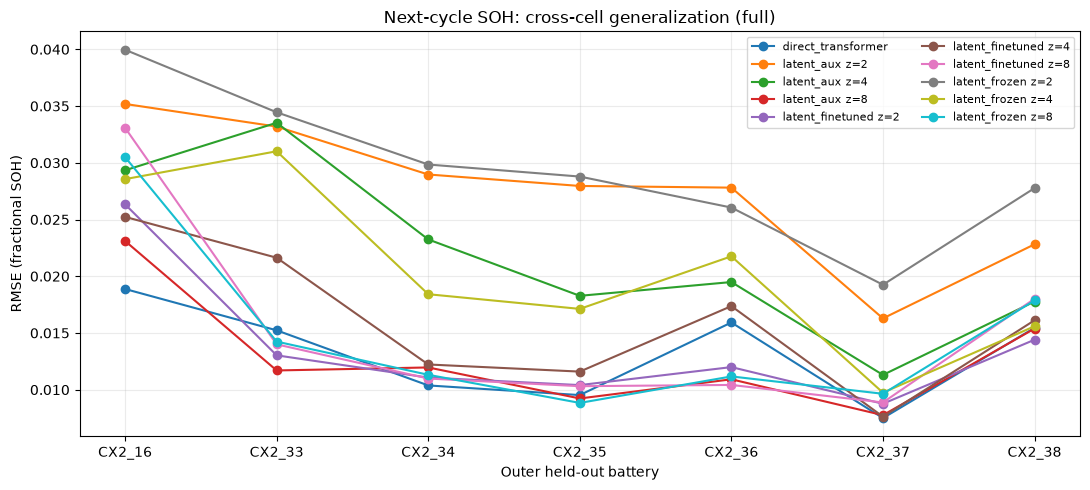

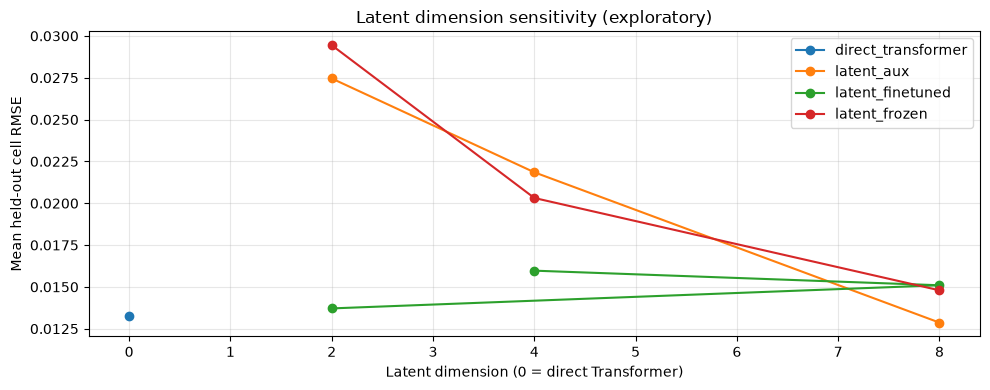

In [18]:
if runs.empty:raise RuntimeError('Run the training cell first')
cell_summary=(runs.groupby(['split','heldout','model','latent_dim'],as_index=False)
 .agg(RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MAE_mean=('MAE','mean'),
      R2_mean=('R2','mean'),MAPE_mean=('MAPE','mean'),n_seeds=('seed','nunique')))
cell_summary.to_csv(RUN_ROOT/'fold_metrics.csv',index=False)
outer=cell_summary[cell_summary.split=='test'].copy()
overall=(outer.groupby(['model','latent_dim'],as_index=False)
 .agg(mean_fold_RMSE=('RMSE_mean','mean'),std_across_folds=('RMSE_mean','std'),
      mean_fold_MAE=('MAE_mean','mean'),mean_R2=('R2_mean','mean'),n_folds=('heldout','nunique'))
 .sort_values('mean_fold_RMSE'))
overall.to_csv(RUN_ROOT/'outer_fold_summary.csv',index=False)
print('Outer held-out folds — report descriptive results (not a tuning target)')
display(overall)
print('Fold-by-fold scores')
display(outer.pivot_table(index='heldout',columns=['model','latent_dim'],values='RMSE_mean').round(5))

# Paired delta on same fold+seed for each latent configuration versus direct Transformer.
base=runs[(runs.split=='test')&(runs.model=='direct_transformer')][['heldout','seed','RMSE']].rename(columns={'RMSE':'baseline_RMSE'})
aug=runs[(runs.split=='test')&(runs.model!='direct_transformer')].copy()
paired=aug.merge(base,on=['heldout','seed'],validate='many_to_one')
paired['relative_RMSE_reduction_pct']=100*(paired['baseline_RMSE']-paired['RMSE'])/paired['baseline_RMSE']
paired.to_csv(RUN_ROOT/'paired_fold_comparisons.csv',index=False)

fig,ax=plt.subplots(figsize=(11,5))
for (model,d),part in outer.groupby(['model','latent_dim']):
    label=model if model=='direct_transformer' else f'{model} z={d}'
    ax.plot(part.heldout,part.RMSE_mean,marker='o',label=label)
ax.set(xlabel='Outer held-out battery',ylabel='RMSE (fractional SOH)',
       title=f'Next-cycle SOH: cross-cell generalization ({MODE})')
ax.grid(alpha=.25);ax.legend(ncol=2,fontsize=8);fig.tight_layout()
fig.savefig(RUN_ROOT/'outer_fold_RMSE.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(10,4))
for _,part in overall.groupby('model'):
    ax.plot(part.latent_dim,part.mean_fold_RMSE,marker='o',label=part.model.iloc[0])
ax.set(xlabel='Latent dimension (0 = direct Transformer)',ylabel='Mean held-out cell RMSE',
       title='Latent dimension sensitivity (exploratory)')
ax.grid(alpha=.3);ax.legend();fig.tight_layout()
fig.savefig(RUN_ROOT/'latent_dimension_sensitivity.png',dpi=180);plt.show()

## 8. Interpreting the study safely

- **A latent advantage must replicate across cells:** One previously favorable held-out cell is insufficient. Assess per-cell paired deltas and how many folds show positive improvement.
- **SOH noise remains unresolved:** The 3% training-only filter is a sensitivity choice, not a verified data correction. Repeating a prespecified no-filter study would help assess robustness.
- **Latent dimension 8 is an expansion, not compression:** Five observed features → eight latent values. Its advantage, if any, need not arise from compression.
- **Cross-cell evaluation is still limited:** All cells originate from a related experimental family; leave-one-cell-out is not cross-protocol or cross-chemistry validation.
- **No inference leakage:** Future-cycle charge features are never passed to the forward prediction. The latent auxiliary *training target* is allowed to use future observations from training cells only.
- **Evaluation population varies by training filter:** Fewer training windows after excluding cycles; all methods within a fold share exactly the same windows.
- **Important:** These models do **next-cycle forecasting**, which differs from the earlier current-cycle SOH *estimation* benchmarks. Compare only with matched next-cycle controls.

### Suggested follow-up (after completing full mode)
Run a **pre-registered no-filter sensitivity** experiment by setting `APPLY_TRAIN_FILTER=False` and using a *new* output folder. Then test 24- and 48-cycle histories with fixed architecture choices, paying attention to decreasing eligible window counts. Final claims require unseen external cells or a separately locked evaluation protocol.